### Data Programming, Coursework 1, 12.11.2025, by G. Ozge Sengil

### Introduction to the Dataset & Current Analysis

Cycling as a form of transportation has become more and more popular in many cities around the world in the last decade. Policies are also promoting cycling for its health benefits, reducing gas emissions to the atmosphere, and also releaving the traffic congestions (Chibwe et al., 2021). Invention and popularisation of public bike-renting and bike-sharing systems contributed rapidly to the number of users in the world, and made it possible to track the user activities such as the duration, destination, arrival, and demand (Eren & Uz, 2020) in relation to environmental variables.

Weather conditions are amongst the most studied correlates for bike sharing demand (Eren & Uz, 2020). It has been suggested by the previous literature that demand is positively correlated with temperature, and negatively correlated with humidity, rain or snow, and windspeed (Kim, 2018).

Season and some other temporal factors  has been found to be strong predictors of bike rental demands in the previous literature. To illustrate, bike rental demands has been fount ot be higher in summer compared to april in some previous studies (Rudloff & Lackner, 2014). Kim (2018) showed that, when it comes to other temporal correlates of this demand, although weekdays are not significantly different from weekends, public holidays are associated with lower demands.


### Dataset

This project will use a bike sharing dataset to evaluate the factors affecting this demand with the aims of predicting the bike mobility in the city. The open-source datasets that are chosen for this task is named 'Bike Sharing' and they are retrieved from the UC Irvine Machine Learning Repository (Fanaee-T, et al., 2013). There are two .csv files associated with this dataset: hour.csv, and day.csv. The datasets contain information about hourly and daily bike rentals in Capital Bike Share System between the years 2011 and 2012, respectively. Corresponding seasonal, weather, and special events information are also contained. The dataset has 13 features with each having 17379 instances. Features are integer, date, continous, categorical or binary variables in representation, but their encoding in datasets is numeric (integer or float). The format of data (.csv) is suitable for numeric and categorical data analysis once read as a dataframe. 


#### **Features of the Dataset**
 * Target (criterion) variables: cnt (count of total bike rentals in day/hour), registered (registered user activity), casual (casual user activity)
 * Predictor variables: season, yr (year), mnth (month), hr (hour, only in hourly dataset), holiday, weekday, workingday, weathersit (weather situation), temp (temperature), atemp (feels-like temperature), hum (humidity), windspeed
 * Target variables are encoded as numbers of real counts
 * tem, atemp, hum, and windspeed are normalized to 0-1, therefore no further scaling is necessary
 * season, yr, hr, mnth, weekday, holiday, workingday, weathersit are encoded with integers to represent categorical values, which is in line with numeric data analysis objectives therefore no further transformation is needed


#### **Reasons for the Selection of Dataset** 
 * It is a publically available dataset.
 * It is already largely structured and very well formatted.
 * It does not include any personal or identification information therefore it can be used ethically.
 * It has behavioral, temporal and predictive richness to it. This dataset provide another oppurtunity to perform a **regression analysis** to uncover the predictive relationship between temporal, weather, and seasonal factors and bike sharing demand.
 * Another exciting opportunity is that dataset provides not only the aggregated user behavior, but registered and casual user behavior as well, so that we can investigate the factors predicting such distinct demands.


#### **Possible Limitations of the Dataset**
 * External rare events (such as city-wide events or holidays) information is not stored.
 * No demographic information is provided so generalization to individuals or groups cannot be made.
 * The data is collected in a single city in a specific period of time; generalizability to other cities and time frames might be low.
 * Dataset does not include information such as location, duration of use, closeness to other public transportation which could be very strong predictors of bike rental counts, in addition to the ones stored in the dataset.



### **Coursework 1 Overview**
The 'Data Inspection' section of the notebook specifically follows this structure:

* Data Inspection
    * **Importing the 'Hourly Bke Rentals' Dataset and Inspecting the Features**
    * **Deriving a Daily Rentals Dataset from Hourly Rentals**
    * **Checking for Missing Values**
    * **Performing Basic Statistics and Data Summary**
    * **Visualizing the Distribution of Key Target Variables**
    * **Statistical Testing for the Skewness**
    * **Data Cleaning by Identifying and Treating the Univariate Outliers**

After this initial data inspection, I will briefly mention the type of analyses I am planning to conduct in the next phase of the project in the following section:

* **Plans for the Phase 2 of Data Analysis**

After that, the notebook will conclude with the following sections:

* **Limitations of the Current (Phase 1) Data Analysis**
* **Ethical and Data Use Considerations**
* **References**

In [69]:
# import necessary packages

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

### Importing the 'Hourly Bike Rentals' Dataset & Inspecting the Features

I will first read the 'hour.csv' data file as pandas dataframe. I will not read the 'day.csv' as yet, since daily rentals can be derived from the hourly rentals. I will derive the daily rentals dataset in the upcoming steps.

In [70]:
# Daily Bike Rentals can be computed from the Hourly Rentals, so no need to read it from the file as yet.

bike_by_hour = pd.read_csv('hour.csv', encoding = 'latin-1')

print('\nHourly Bike Rentals Column Names: ')
print(bike_by_hour.columns) # Show the names of the columns

print('\nHourly Bike Rentals Info: ')
bike_by_hour.info() # Show the information regarding the feature names, sample size, and data type for each feature

print('\nHourly Bike Rentals: ')
bike_by_hour.head(4) # Show the first 4 rows from the dataset along with the heading


Hourly Bike Rentals Column Names: 
Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')

Hourly Bike Rentals Info: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13


* The data, as shown above, succesfully read as a Pandas DataFrame. This format is in line with our data analysis plans especially considering it would allow us to store and manipulate both numeric and categorical variables. Floats and integers are already represented with 64 bits, therefore no need to change that for any variables. All of the features are originally stored as either float or integer (numeric) (except for the date), which would indicate there is no need to transform any variable types for our numeric data analysis.

* Variables named: temp, atemp, hum, windspeed, casual, registered, cnt -- are already numeric and they should stay numeric.

* But variables named: season, yr, mnth, holiday, weekday, workingday, weathersit, and hr -- they are ordinal or categorical -- but represented with integers.

* Both floats and integers are represented with 64 bits -- therefore there is no need to allocate more representational space for them.

### Deriving a Daily Rentals Dataset from Hourly Rentals

I will now derive the 'daily rentals' from the read hourly bike rentals dataframe by grouping the whole dataset by the date (of the day). After that, I will perform a comparison between my derived version and the verison that is being read directly from the 'day.csv' file to see if they are identical (they should be identical).

In [71]:
# Creating the Daily Bike Rentals DataFrame from Hourly Bike Rentals

    # group the data by day [by using the column title of interest 'dteday'] 
    # so that I can have daily aggregated data frame as well in addition to hourly one

bike_by_day = bike_by_hour.groupby('dteday').agg({
    'season' : 'first', # take the season info
    'yr' : 'first', # take the year info
    'mnth' : 'first',
    'holiday' : 'first',
    'weekday' : 'first',
    'workingday' : 'first',
    'weathersit' : 'mean', # take the mean of the weather situation for the day
    'temp' : 'mean',
    'atemp' : 'mean',
    'hum' : 'mean',
    'windspeed' : 'mean',
    'casual' : 'sum', # take the sum of casual user activity
    'registered' : 'sum', # take the sum of registered user activity
    'cnt' : 'sum' # take the sum of total rents for the day
}).reset_index()

print(bike_by_day.head(4)) # Show the first 4 rows

       dteday  season  yr  mnth  holiday  weekday  workingday  weathersit  \
0  2011-01-01       1   0     1        0        6           0    1.583333   
1  2011-01-02       1   0     1        0        0           0    1.956522   
2  2011-01-03       1   0     1        0        1           1    1.000000   
3  2011-01-04       1   0     1        0        2           1    1.043478   

       temp     atemp       hum  windspeed  casual  registered   cnt  
0  0.344167  0.363625  0.805833   0.160446     331         654   985  
1  0.363478  0.353739  0.696087   0.248539     131         670   801  
2  0.196364  0.189405  0.437273   0.248309     120        1229  1349  
3  0.200000  0.212122  0.590435   0.160296     108        1454  1562  


In [72]:
day_ori = pd.read_csv('day.csv') # Read the original daily bike rentals from the source

comp = pd.merge(day_ori, bike_by_day, on='dteday', suffixes = ('_orig','_calc')) # Compare and see whether the difference is zero
print('The number of different values between Daily Rentals Original and Calculated :')
print((comp['cnt_orig'] - comp['cnt_calc']).abs().sum())
if (comp['cnt_orig'] - comp['cnt_calc']).abs().sum() == 0:
    print('\nThe Daily Bike Rentals Dataframe derived from the Hourly Rentals is numerically the same as the original Daily Rentals.')

The number of different values between Daily Rentals Original and Calculated :
0

The Daily Bike Rentals Dataframe derived from the Hourly Rentals is numerically the same as the original Daily Rentals.


 * Aggregated and grouped daily rentals data frame is identical the one authors originally uploaded. We can do further processing on it.

### Checking for Missing Values

In [73]:
# missing values in hourly bike rentals data frame 
print('Number of Missing Values in Hourly Bike Rentals for Each Feature: ')
print(bike_by_hour.isnull().sum())
print('\nTotal Number of Missing Values in Hourly Bike Rentals Dataframe: ')
print(bike_by_hour.isnull().sum().sum())

print('\n')

# missing values in daily bike rentals data frame 
    # since this one is derived from the hourly one, should not have any missing values as well, but will check anyway
print('Number of Missing Values in Bike By Day for Each Feature: ')
print(bike_by_day.isnull().sum())
print('\nTotal Number of Missing Values in Bike by Day Dataframe: ')
print(bike_by_day.isnull().sum().sum())

# no missing data in the data frames we have read from the original source or created. 

Number of Missing Values in Hourly Bike Rentals for Each Feature: 
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Total Number of Missing Values in Hourly Bike Rentals Dataframe: 
0


Number of Missing Values in Bike By Day for Each Feature: 
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Total Number of Missing Values in Bike by Day Dataframe: 
0


 * No missing values are found in either dataframes (daily rentals and hourly rentals).

### Perform Basic Statistics and Data Summary
* First, I perform some basic statistics such as mean, standard deviation, min and max, and 25%, 50%, and 70% by using built-in functions, for only numeric features to inspect.

In [74]:
print('\nDaily Bike Rentals - Data Summary :')
display(bike_by_day.describe())

print('\nHourly Bike Rentals - Data Summary :')
display(bike_by_hour.describe())


Daily Bike Rentals - Data Summary :


,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.429347,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.435930,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.041667,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.291667,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,1.681159,0.655417,0.608602,0.730208,0.233215,1096.000000,4776.500000,5956.000000
max,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000



Hourly Bike Rentals - Data Summary :


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


### Visualizing the Distribution of Key Target Variables

* Main target variables in this dataset are: 'cnt', 'registered', and 'casual', all standing for count of rentals. 'cnt' will be relevant as the main regression target, 'registered' and 'casual' can potentially give more information about the seasonal and temporal patterns.
* Since 'counts' data are usually skewed, before deciding which method(s) to use to treat univariate outliers, I wanteed to visualize the target distributions to inspect for any skewness.

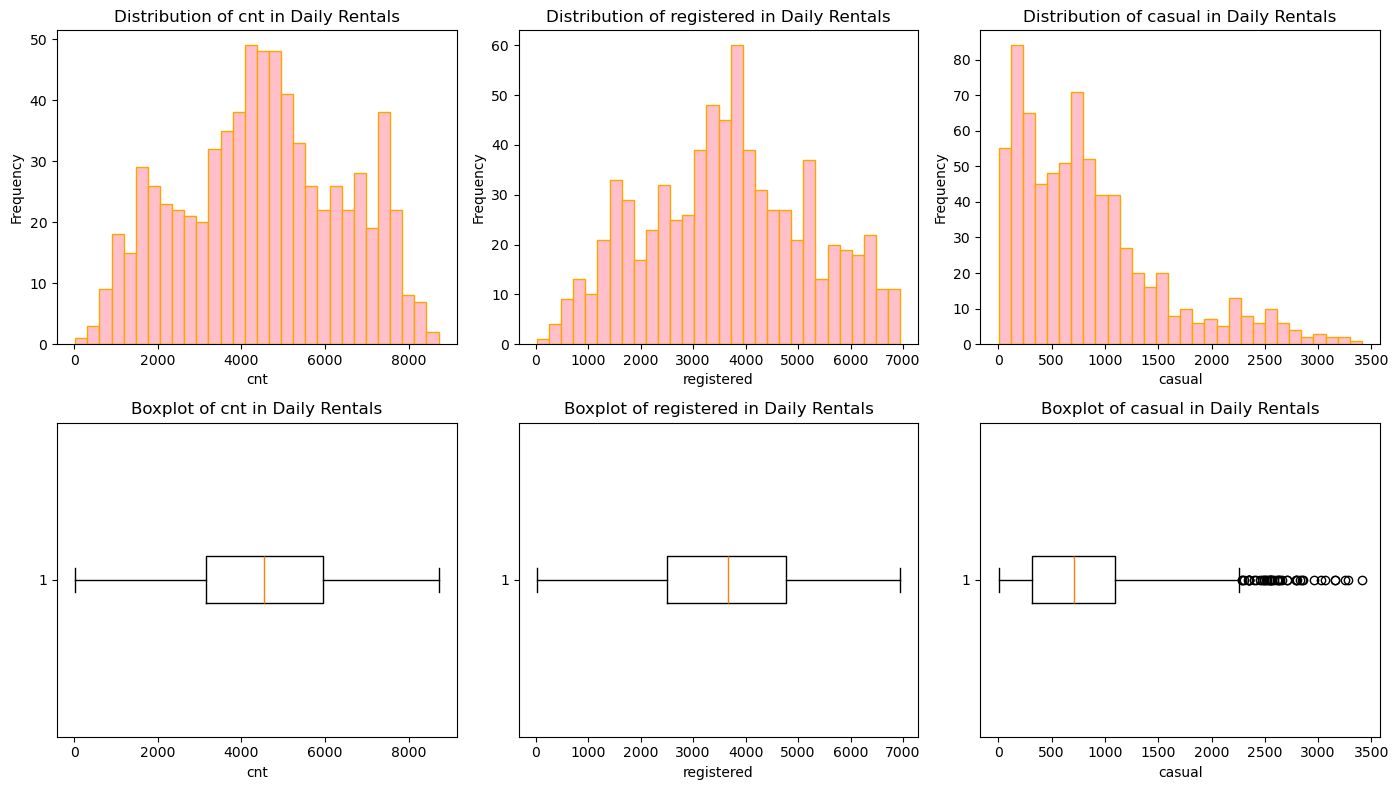

In [75]:
# Visualizing for 'Daily Bike Rentals'

targets = ['cnt', 'registered', 'casual'] 

target_vis_day = bike_by_day.copy() 

plt.figure(figsize = (14,8))

for i, var in enumerate(targets):
    if var in target_vis_day.columns: # only do this if the column is present
        plt.subplot(2,3,i+1)
        plt.hist(target_vis_day[var], bins=30, edgecolor = 'orange', color = 'pink')
        plt.title(f'Distribution of {var} in Daily Rentals')
        plt.xlabel(var)
        plt.ylabel('Frequency')


        plt.subplot(2,3,i+4)
        plt.boxplot(target_vis_day[var], vert=False)
        plt.title(f'Boxplot of {var} in Daily Rentals')
        plt.xlabel(var)

    else:
        print('column not found in dataframe')

plt.tight_layout()
plt.show()

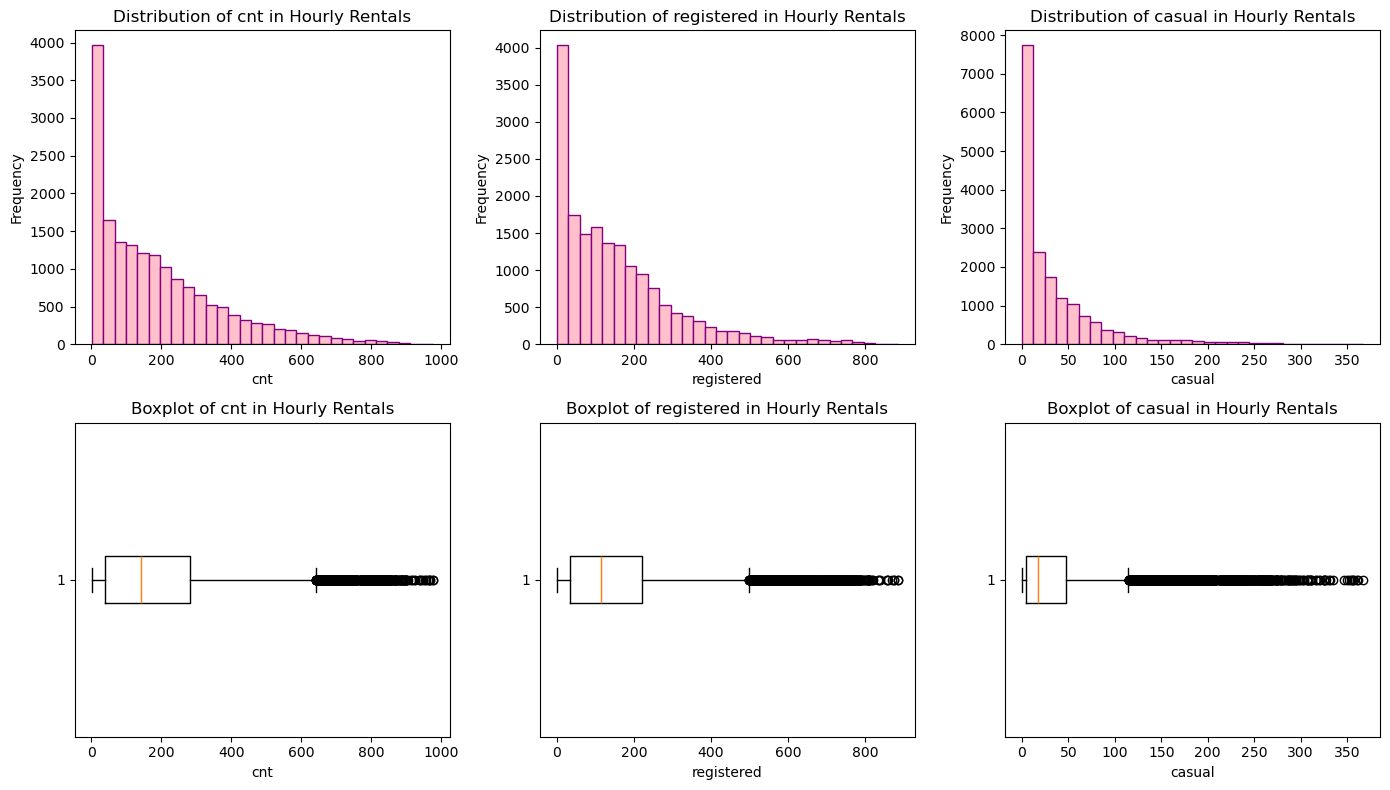

In [76]:
# Visualizing for 'Hourly Bike Rentals'

targets = ['cnt', 'registered', 'casual'] 

target_vis_hour = bike_by_hour.copy() 

plt.figure(figsize = (14,8))

for i, var in enumerate(targets):
    if var in target_vis_hour.columns: # only do this if the column is present
        plt.subplot(2,3,i+1)
        plt.hist(target_vis_hour[var], bins=30, edgecolor = 'purple', color = 'pink')
        plt.title(f'Distribution of {var} in Hourly Rentals')
        plt.xlabel(var)
        plt.ylabel('Frequency')


        plt.subplot(2,3,i+4)
        plt.boxplot(target_vis_hour[var], vert=False)
        plt.title(f'Boxplot of {var} in Hourly Rentals')
        plt.xlabel(var)

    else:
        print('column not found in dataframe')

plt.tight_layout()
plt.show()

The initial visualization of three target variables that are numerically (continous) coded reveals the following:

  **For Daily Bike Rentals:**

* distribution of 'count' and 'registered' (total number of bike rentals in the same day and the registered user bike rentals) follows a normal like (Gaussian) distribution
* 'count' and 'registered' boxplots do not show any outliers, although this needs to be checked statistically with other methods as well.
* the distribution of 'casual' (casual user rentals) seems to be skewed towards right
* boxplot visualization for 'casual' shows many outliers after the right whisker

Although the visual inspection does not show any univariate outliers for 'count' and 'registered' in the boxplots, I will still statistically identify the outliers from the 'count' and 'registered' by identifying the values that are more then 3 standard deviation away from the mean in the following sections. The results might be different since boxplot uses quartile boundaries, and not standard deviation rules to identify outliers. By doing so I will perform a Winsorization by replacing them with the upper and lower boundaries since they seem to be somehow normally disributed. 

  **For Hourly Bike Rentals**

* distribution of all three target variables in this dataframe shows visual evidence for strong right skew.
* boxplots for all three target variables shows large numbers of outliers beyond the upper quartile boundary and right whisker of boxplots.


  **Univariate Outliers Detection and Treatment Strategy**
In order to decide on the exact methodology to deal with the outliers of skewed 'casual' in daily bike rentals, and the whole hourly rental targetsi I want to statistically check for the visually inspected 'skewness' since visual inspection can be misleading. If the skewness is found to be strong, I will consider doing a log-transform for these features'  outliers instead of Winsorisation, since standard deviation based treatment of outliers assumes a normal distribution. Log-transforms are heavily used when the data is strongly right-skewed (such as counts).

For the statistical inspection of skewness, I am using the following rule of thumb:
* if the value is 0 : perfectly symmetrical distribution (no skew)
* if the value > 0 : right skew
* if the value > 0 : left skew

* value between 0.5 and 1.0 : moderate skew
* value > 1 : strong skew (so I might consider transformation)

### Statistical Testing for Skewness

In [77]:
for var in targets:
    if var in target_vis_day.columns:
        print(f"daily rentals {var} skewness: {target_vis_day[var].skew():.4f}")

daily rentals cnt skewness: -0.0474
daily rentals registered skewness: 0.0437
daily rentals casual skewness: 1.2665


In [78]:
for var in targets:
    if var in target_vis_hour.columns:
        print(f"hourly rentals {var} skewness: {target_vis_hour[var].skew():.4f}")

hourly rentals cnt skewness: 1.2774
hourly rentals registered skewness: 1.5579
hourly rentals casual skewness: 2.4992


Test for skewness, when the above described rule of thumb followed, suggest that:
* skewness of 'cnt' and 'registered' in daily rentals are only moderate, and hence Winsorization would work for these variables, whereas, 'casual' would benefit best from a log-transformation to treat the outliers.
* skewness of all target variables in hourly rentals are strong, so these variables would benefit from a log-transformation instead of Winsorization.

### Data Cleaning by Identifying and Treating the Univariate Outliers

* For variables 'cnt', 'registered', and 'casual' in both dataframes, I will identify the outliers at 3 standard deviation (SD) boundary, and will perform Winsorization by replacing a value that is more than 3 SDs away from the mean of the column with either negative 3 SD or positive 3 SD depending on their quartile. This will allow me to perform further statistical testing without actually losing any data, and I will make sure not to change the original data.
* Then for the same variables for both dataframes, I will perform a log transform to push the right tail outliers to the left boundary.

In [79]:
def replace_univar_outliers(df,feats,df_name='dataframe'): # a function to identify and replace the univariate outliers at 3SD boundary

    # replaces univariate outliers that are more than 3STD away from the mean with + or - 3STD of the column
    # df : pandas dataframe
    # feats : a list containing column/feature names to be winsorized
    # df_name : string name of the dataframe for a readable output
    
    df_new = df.copy() # to keep the original untouched
    
    for feat in feats:
        if np.issubdtype(df_new[feat].dtype, np.number): # do this only for the columns with numeric data type (and not try on text or date columns)
            mean_feat = df_new[feat].mean()
            std_feat = df_new[feat].std()
            
            upper_bound = mean_feat + 3.*std_feat
            lower_bound = mean_feat - 3.*std_feat

                        # ensure some transparency in the process by calculating the number of values winsorized
            
            winsorized_upper = (df_new[feat] > upper_bound).sum() # the number of values winsorization is applied
            winsorized_lower = (df_new[feat] < lower_bound).sum() # the number of values winsorization is applied
            overall_values = len(df_new[feat]) # the number of values in the column

            # replace the values

            df_new[feat] = np.where(df_new[feat] > upper_bound, upper_bound,
                                    np.where(df_new[feat] < lower_bound, lower_bound, 
                                             df_new[feat]))
            

            print(f' {feat}: {winsorized_upper+winsorized_lower} values winsorized from a total of {overall_values} in {df_name}'
                  f'( {winsorized_upper} values above +3 std, {winsorized_lower} values below -3 std)')
     
    return df_new

In [80]:
features_winsorize = ['cnt','registered','casual'] # target variables to be winsorized

day_winsorized = replace_univar_outliers(bike_by_day, features_winsorize,'daily bike rentals') # winsorized daily bike rentals
hour_winsorized = replace_univar_outliers(bike_by_hour, features_winsorize, 'hourly bike rentals') # winsorized hourly bike rentals

# check for the changes in data descriptions after winsorization

%config InteractiveShell.ast_node_interactivity = 'all' # to be able to print all outputs at once

print('\n')
print('\n')

print('Daily Bike Rentals Before and After Winsorization:')
bike_by_day[features_winsorize].describe()
day_winsorized[features_winsorize].describe()

print('\nHourly Bike Rentals Before and After Winsorization:')
bike_by_hour[features_winsorize].describe()
hour_winsorized[features_winsorize].describe()

%config InteractiveShell.ast_node_interactivity = 'last_expr' # to be able to go to default settings


 cnt: 0 values winsorized from a total of 731 in daily bike rentals( 0 values above +3 std, 0 values below -3 std)
 registered: 0 values winsorized from a total of 731 in daily bike rentals( 0 values above +3 std, 0 values below -3 std)
 casual: 8 values winsorized from a total of 731 in daily bike rentals( 8 values above +3 std, 0 values below -3 std)
 cnt: 244 values winsorized from a total of 17379 in hourly bike rentals( 244 values above +3 std, 0 values below -3 std)
 registered: 371 values winsorized from a total of 17379 in hourly bike rentals( 371 values above +3 std, 0 values below -3 std)
 casual: 467 values winsorized from a total of 17379 in hourly bike rentals( 467 values above +3 std, 0 values below -3 std)




Daily Bike Rentals Before and After Winsorization:

Hourly Bike Rentals Before and After Winsorization:


* Winsorization is performed for both daily and hourly bike rentals and a winsorized version of both dataframe has been created by keeping the originals intact.
  
* Implications for daily bike rentals:

  
  * cnt: 0 values winsorized from a total of 731 in daily bike rentals( 0 values above +3 std, 0 values below -3 std)
  * registered: 0 values winsorized from a total of 731 in daily bike rentals( 0 values above +3 std, 0 values below -3 std)
  * casual: 8 values winsorized from a total of 731 in daily bike rentals( 8 values above +3 std, 0 values below -3 std)
  * For the 'counts' and 'registered' columns, no outliers are detected at these boundaries, which is in line with out observations in boxplot visualizations.
  * For the 'casual' column, 8 values that are greater than 3 std are winsorized, which in turn decreased the mean and standard deviation very slightly for this target (as can be seen from the printed tables showing the before and after descriptions of target variables). Although winsorization is slightly normalizing for the 'casual', I believe this variable will benefit from log-transformation better considering this distribution is strongly skewed.

* Implications for hourly bike rentals:

  
  * cnt: 244 values winsorized from a total of 17379 in hourly bike rentals( 244 values above +3 std, 0 values below -3 std)
  * registered: 371 values winsorized from a total of 17379 in hourly bike rentals( 371 values above +3 std, 0 values below -3 std)
  * casual: 467 values winsorized from a total of 17379 in hourly bike rentals( 467 values above +3 std, 0 values below -3 std)
  * Hourly rentals, as expected and as seen from the histograms and boxplots, has more outliers, even for the first two targets. That might be due to the non-aggregated nature of the hourly data, and affects of independent elements such as rush hours or events.
  * It is worth noting that for all target variables, only upper bound outliers are detected. (There are no outliers below the -3 std boundary).

In short:

* Hourly dataset showed more spikes and short term variability, whereas daily dataset showed more stability.
* By performing Winsorization, I decreased the effect of such spikes and short term variabilities in the data without actually losing any data points. Regression analysis would favor such an approach.


* Next, I will perform log-transformation on target variables as a means of treating univariate outliers. I will use log(x+1) mathematical notion to be able to not affected from zeros. Log-transformation as such is a better approximation of normal distribution and linear relationships between the predictors and targets.

In [81]:
def logtrans_univ_outliers(df, feats, df_name='dataframe'):

    # this function performs a log(x+1) transform for the given columns.
    # the output is a new dataframe and the original dataframe is preserved.
    # the new features are added to the dataframe with the _log suffix

    # df : dataframe
    # feats : a list contianing the names of the target variables
    # df_name : string name of the dataframe for a readable output

    df_new = df.copy()


    for feat in feats:
        df_new[feat+'_log'] = np.log(df_new[feat] + 1)
        print(f'A new log-transformed column {feat}_log has been created after {df_name}')

    return df_new

In [82]:
features_logtrans = ['cnt','registered','casual'] # target variables to be log-transformed

# perform the log-transformation for all target variables in both daily and hourly rentals dataframes
day_logtransformed = logtrans_univ_outliers(bike_by_day, features_logtrans,'daily rentals')
hour_logtransformed = logtrans_univ_outliers(bike_by_hour, features_logtrans,'hourly rentals')

print('\nDaily Bike Rentals Column Names After _log Features Are Added: ')
print(day_logtransformed.columns) # Show the names of the columns

print('\nHourly Bike Rentals Column Names After _log Features Are Added: ')
print(hour_logtransformed.columns) # Show the names of the columns

A new log-transformed column cnt_log has been created after daily rentals
A new log-transformed column registered_log has been created after daily rentals
A new log-transformed column casual_log has been created after daily rentals
A new log-transformed column cnt_log has been created after hourly rentals
A new log-transformed column registered_log has been created after hourly rentals
A new log-transformed column casual_log has been created after hourly rentals

Daily Bike Rentals Column Names After _log Features Are Added: 
Index(['dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday',
       'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual',
       'registered', 'cnt', 'cnt_log', 'registered_log', 'casual_log'],
      dtype='object')

Hourly Bike Rentals Column Names After _log Features Are Added: 
Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'cas

* The above output shows the _log columns are created inside these new dataframes containing log-transformed targets.

### Plans for the Phase 2 of Data Analysis

* In the 2nd phase of this project, I will start by developing some baseline linear regression models to predict the daily and hourly bike rental demands from the weather and temporal predictors. This initial model will be a comparison point for the later machine learning regression models. The aim is not only to produce accurate predictions, but also to be able to compare the performance of different models.
* The bike rental 'counts' will be modeled as a function of weather conditions (temperature, felt-temperature, humidity, windspeed), weather situation, and temporal factors (weekend, weekday, working day, season, month or holiday). The benchmark linear regression model will provide coefficients and will be interpreted based on the directionality and the strength of the predictions.
* After this benchmark model, I will develop some machine learning regression models to be able to better capture non-linear predictive relationships and possible interactions between the predictors. I might use Random Forest Regressor or Gradient Boosting models since they would allow me to treat outliers and non-linear effects without being affected by skewness or needing a log-transformation.

### Ethical and Data Use Considerations

The dataset is publically available in the https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset in UC Irvine Machine Learning Repository under an open licence and for the eductional and research use. The origins of the data is described transparently in this notebook. The dataset does not include any personal or identification information, they are rather averaged across day or hour without providing any personal or behavioral data, or location tracking. Therefore, confidentiality, privacy and data protection concerns are not raised in the use of the data in this project. 

Since the data does not include any demographic information, results would be informative in terms of the patterns of user behavior and not of characteristics of users. This dataset does not allow us to make causal claims, so the analysis results can not be interpreted in terms of the motivations or psychological underpinnings of the users.

All operations in this notebook are documented and reproducible in notebook. Since the original dataset is free of missing values, no syntetic data have been created, which is another factor contributing to the reproducibility.

## Limitations of the Current (Phase 1) Data Analysis

* The univariate outliers in target variables are treated with different methodologies.
* Only univariate outliers are identified and treated. Future data analysis might include multivariate outlier detection and treatment (such as Mahalanobis distance calculations).
    

### References

 * Chibwe, J., Heydari, S., Imani, A. F., & Scurtu, A. (2021). An exploratory analysis of the trend in the demand for the London bike-sharing system: From London Olympics to Covid-19 pandemic. Sustainable Cities and Society, 69, 102871.
 * Eren, E., & Uz, V. E. (2020). A review on bike-sharing: The factors affecting bike-sharing demand. Sustainable cities and society, 54, 101882.
 * Fanaee-T, H. (2013). Bike Sharing [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894.
 * Kim, K. (2018). Investigation on the effects of weather and calendar events on bike-sharing according to the trip patterns of bike rentals of stations. Journal of transport geography, 66, 309-320. https://doi.org/10.1016/j.jtrangeo.2018.01.001
 * Rudloff, C., & Lackner, B. (2014). Modeling demand for bikesharing systems: neighboring stations as source for demand and reason for structural breaks. Transportation Research Record, 2430(1), 1-11. https://doi.org/10.3141/2430-01 
